<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/08_year_check_andrew.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/notebooks/08_year_check_andrew.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 4: how long does the model stay valid, and should year stay an input?

*AI-assisted: every code and markdown cell was generated with Claude (Opus 5.5) on 2026-11-10 and reviewed, run and edited by Andrew Reicin. None of this text is for the slides or report.*

Train notebook 04's tree on games published up to **2016**, then test it on each later year (**2017 to 2021**) one at a time, as in Session 19's time split. Ground rule 2's random split does not apply here, and the model is not re-tuned.

- **Training years:** every game up to 2016 (same games as notebook 04, cut by year).
- **2022 and 2023 left out:** the data was downloaded in January 2022, so those games were only rated by early raters.
- **Valid** is judged two ways: (a) error within 10% of the model's cross-validated error on its own training years; (b) R² above 0, i.e. better than guessing that year's average rating.
- Everything is run **with and without year of publication** as an input.

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-10. Imports; reviewed and edited by Andrew Reicin.
# --- Andrew Reicin: Task 4, year-by-year test of how long the rating model stays valid, with and without year as an input ---
# [AI-assisted] Claude (Opus 5.5), 2026-11-10. Every code and markdown cell in this notebook was generated with Claude and reviewed, run and edited by Andrew Reicin.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_val_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

FIG_DIR = "../figures" if os.path.isdir("../figures") else "."
def save(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches="tight")

COLORS = {"Year as an input": "tab:blue", "Year removed": "tab:orange", "Dummy (training mean)": "0.5"}

## 1. Games and the year split

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-10. Load the same games as notebook 04 and split by year; reviewed and edited by Andrew Reicin.
BASE = "https://raw.githubusercontent.com/24sahil25-source/BA305-BoardGameGeek-Fall2026/main/data/"
games = pd.read_csv(BASE + "bgg_clean.csv")

# ROWS: notebook 04's rows, games with every input known. Replace with Task 1's choice on missing values once it is posted.
numeric_cols = ["yearpublished", "minplayers", "maxplayers", "minplaytime", "maxplaytime", "minage", "n_mechanics", "n_categories"]
data = games.dropna(subset=numeric_cols + ["boardgamemechanic", "boardgamecategory", "average"]).reset_index(drop=True)

CUTOFF = 2016                     # train on games published up to this year
TEST_YEARS = range(2017, 2022)    # test on each of these years; 2022-2023 left out (rated before most people played them)

train_df = data[data["yearpublished"] <= CUTOFF]
print("training games (up to", CUTOFF, "):", len(train_df))
print("left out, published 2022-2023:", int((data["yearpublished"] >= 2022).sum()))
data[data["yearpublished"].isin(TEST_YEARS)]["yearpublished"].astype(int).value_counts().sort_index().to_frame("test games")

training games (up to 2016 ): 13061
left out, published 2022-2023: 106


,test games
yearpublished,
2017,1155
2018,1168
2019,1105
2020,783
2021,604


In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-10. Build the inputs as notebook 04 does, counting the common mechanics and categories on the training years only; reviewed and edited by Andrew Reicin.
top_mech = train_df["boardgamemechanic"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(20).index
top_cat = train_df["boardgamecategory"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(15).index

def build_inputs(frame):
    X = frame[numeric_cols].copy()
    for col in ["minplayers", "maxplayers", "minplaytime", "maxplaytime"]:
        X[col] = np.log10(X[col])
    mech = frame["boardgamemechanic"].str.get_dummies(sep="|").reindex(columns=top_mech, fill_value=0).add_prefix("mech_")
    cat = frame["boardgamecategory"].str.get_dummies(sep="|").reindex(columns=top_cat, fill_value=0).add_prefix("cat_")
    return pd.concat([X, mech, cat], axis=1)

X_train = build_inputs(train_df)
y_train = train_df["average"]
print("inputs:", X_train.shape[1], "columns")

inputs: 43 columns


## 2. The model, with and without year

Notebook 04's tuned tree (max_depth 10, min_samples_leaf 50), fitted on the training years. Not re-tuned, as the task says.

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-10. Fit both versions and get the reference error on the training years; reviewed and edited by Andrew Reicin.
def make_model():
    return DecisionTreeRegressor(max_depth=10, min_samples_leaf=50, random_state=0)

versions = {"Year as an input": list(X_train.columns),
            "Year removed": [c for c in X_train.columns if c != "yearpublished"]}

models, reference = {}, {}
for name, cols in versions.items():
    models[name] = make_model().fit(X_train[cols], y_train)
    # Reference: cross-validated error within the training years (5 folds, shuffled)
    folds = -cross_val_score(make_model(), X_train[cols], y_train, cv=KFold(n_splits=5, shuffle=True, random_state=0),
                             scoring="neg_root_mean_squared_error")
    reference[name] = folds.mean()
    print(f"{name}: cross-validated RMSE on 1-{CUTOFF} games = {folds.mean():.3f} (folds {np.round(folds, 3)})")

dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
print("Dummy prediction for every game: the training mean,", round(y_train.mean(), 3))

Year as an input: cross-validated RMSE on 1-2016 games = 0.694 (folds [0.69  0.695 0.686 0.698 0.7  ])


Year removed: cross-validated RMSE on 1-2016 games = 0.714 (folds [0.712 0.709 0.711 0.717 0.722])
Dummy prediction for every game: the training mean, 6.257


## 3. Score every test year

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-10. Error, average miss and R² for each test year, next to the dummy; reviewed and edited by Andrew Reicin.
rows = []
for year in TEST_YEARS:
    test = data[data["yearpublished"] == year]
    X_test = build_inputs(test)
    y_test = test["average"]
    preds = {name: models[name].predict(X_test[cols]) for name, cols in versions.items()}
    preds["Dummy (training mean)"] = dummy.predict(X_test)
    for name, p in preds.items():
        rows.append({"test year": year, "model": name, "games": len(test),
                     "RMSE": np.sqrt(mean_squared_error(y_test, p)), "MAE": mean_absolute_error(y_test, p),
                     "R2": r2_score(y_test, p), "average miss (pred - actual)": np.mean(p - y_test),
                     "average actual": y_test.mean(), "average predicted": np.mean(p)})
by_year = pd.DataFrame(rows)
by_year.pivot(index="test year", columns="model", values=["RMSE", "R2", "average miss (pred - actual)"]).round(3)

RMSE                                \
model     Dummy (training mean) Year as an input Year removed   
test year                                                       
2017                      0.881            0.639        0.747   
2018                      0.974            0.717        0.816   
2019                      1.048            0.727        0.846   
2020                      1.225            0.860        1.002   
2021                      1.353            0.915        1.066   

                             R2                                \
model     Dummy (training mean) Year as an input Year removed   
test year                                                       
2017                     -0.511            0.206       -0.087   
2018                     -0.643            0.110       -0.155   
2019                     -1.125           -0.023       -0.386   
2020                     -1.750           -0.355       -0.838   
2021                     -2.580           -0.639       -1.221   

          average miss (pred - actual)                                
model            Dummy (training mean) Year as an input Year removed  
test year                                                             
2017                            -0.513           -0.142       -0.371  
2018                            -0.609           -0.255       -0.464  
2019                            -0.762           -0.371       -0.569  
2020                            -0.978           -0.552       -0.743  
2021                            -1.149           -0.655       -0.839

The model's error rises from 0.64 (2017) to 0.92 (2021) and it under-predicts more each year (average miss -0.14 to -0.66). It still beats the dummy in every year.

## 4. How long does it stay valid?

- **(a)** RMSE within 10% of the model's cross-validated RMSE on its own training years.
- **(b)** R² above 0: better than guessing that year's own average rating.

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-10. Apply both tests to each test year; reviewed and edited by Andrew Reicin.
THRESHOLD = 0.10
valid_rows = []
for name in versions:
    yr = by_year[by_year["model"] == name].set_index("test year")
    limit = reference[name] * (1 + THRESHOLD)
    for year, r in yr.iterrows():
        valid_rows.append({"model": name, "test year": year, "RMSE": round(r["RMSE"], 3), "limit for (a)": round(limit, 3),
                           "(a) RMSE within 10%": "yes" if r["RMSE"] <= limit else "no",
                           "R2": round(r["R2"], 3), "(b) R2 above 0": "yes" if r["R2"] > 0 else "no",
                           "RMSE vs reference": f"{r['RMSE'] / reference[name] - 1:+.0%}"})
validity = pd.DataFrame(valid_rows).set_index(["model", "test year"])
validity

RMSE  limit for (a) (a) RMSE within 10%     R2  \
model            test year                                                    
Year as an input 2017       0.639          0.763                 yes  0.206   
                 2018       0.717          0.763                 yes  0.110   
                 2019       0.727          0.763                 yes -0.023   
                 2020       0.860          0.763                  no -0.355   
                 2021       0.915          0.763                  no -0.639   
Year removed     2017       0.747          0.786                 yes -0.087   
                 2018       0.816          0.786                  no -0.155   
                 2019       0.846          0.786                  no -0.386   
                 2020       1.002          0.786                  no -0.838   
                 2021       1.066          0.786                  no -1.221   

                           (b) R2 above 0 RMSE vs reference  
model            test year                                   
Year as an input 2017                 yes               -8%  
                 2018                 yes               +3%  
                 2019                  no               +5%  
                 2020                  no              +24%  
                 2021                  no              +32%  
Year removed     2017                  no               +5%  
                 2018                  no              +14%  
                 2019                  no              +19%  
                 2020                  no              +40%  
                 2021                  no              +49%

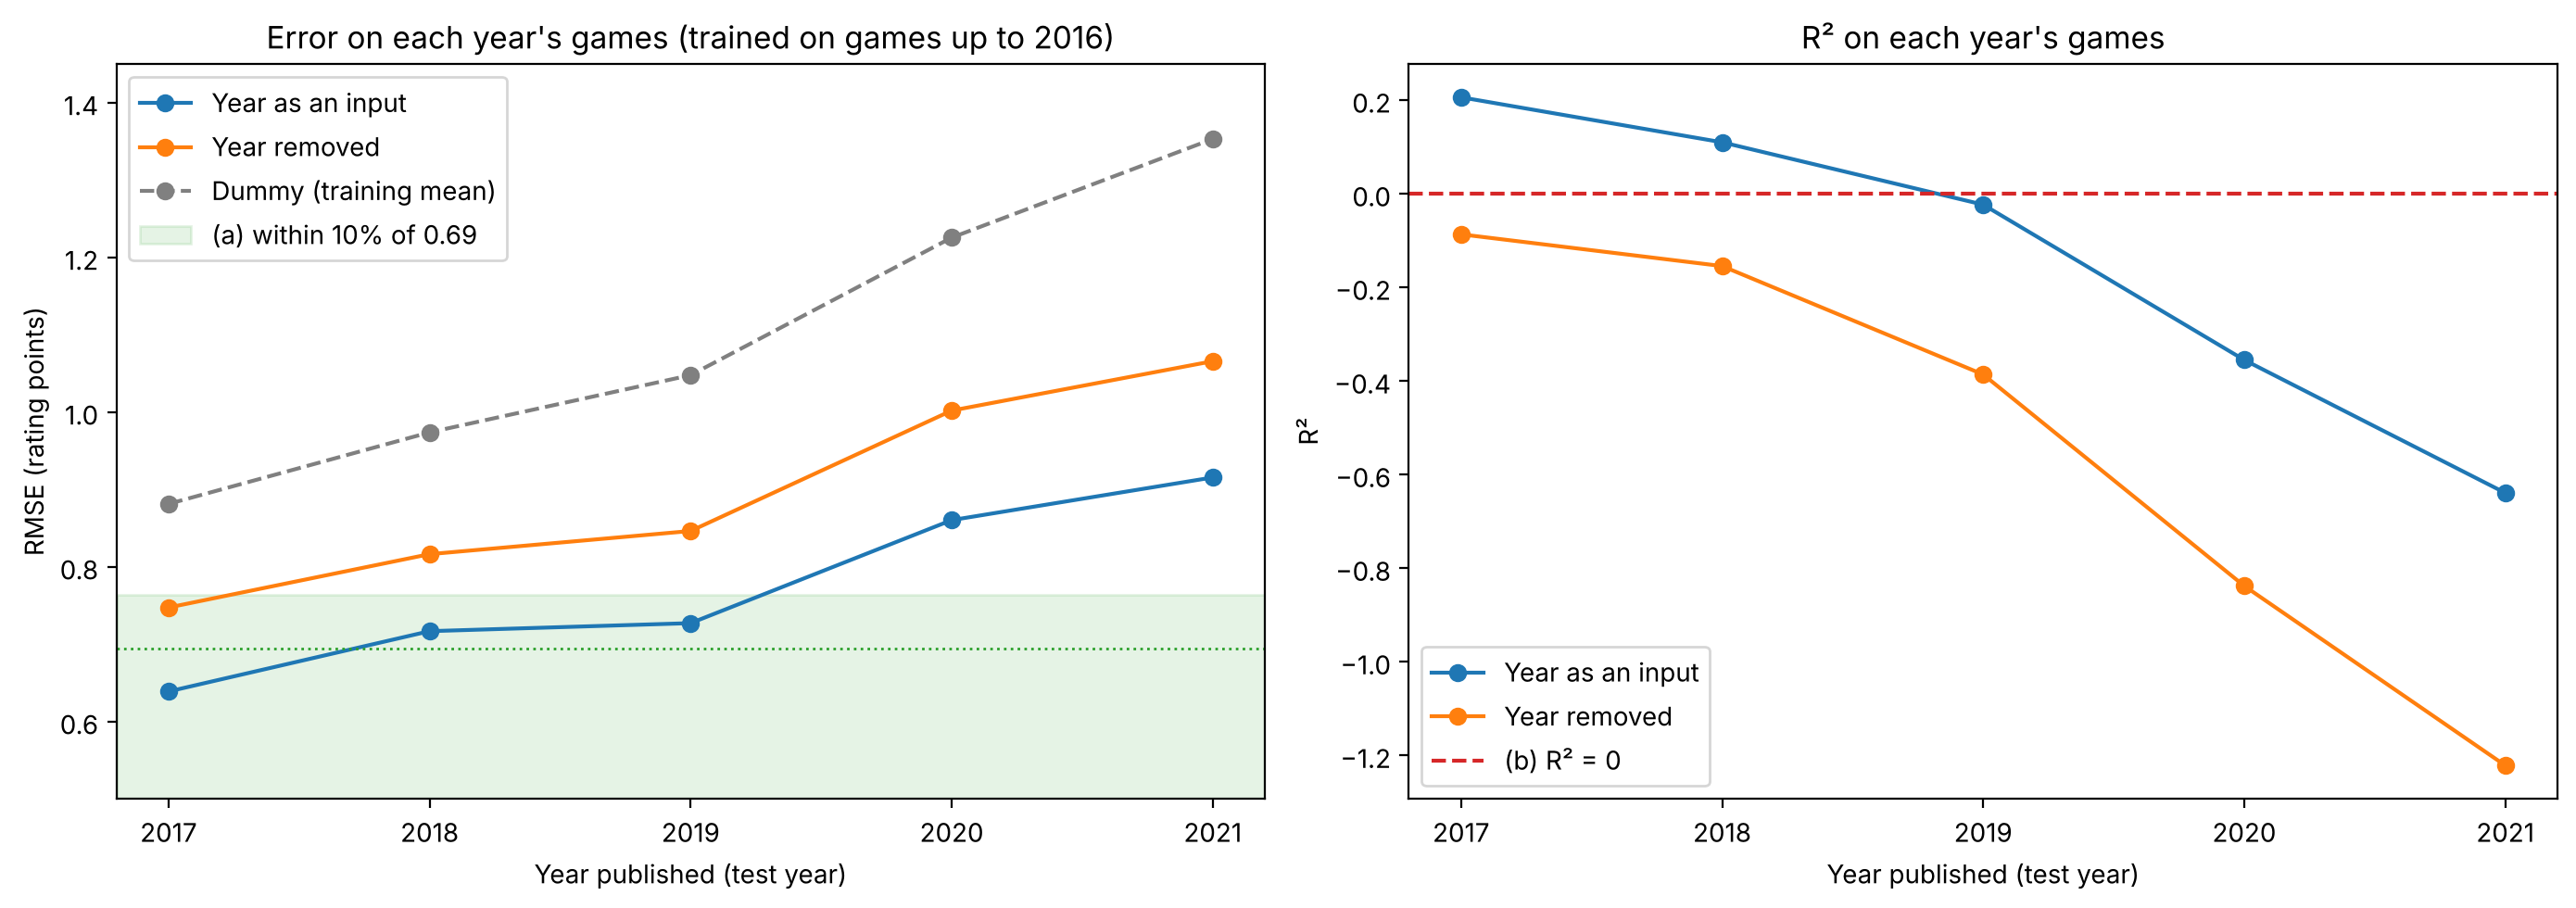

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-10. Figure: error and R² by test year, with both tests marked; reviewed and edited by Andrew Reicin.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
years = list(TEST_YEARS)

for name in versions:
    yr = by_year[by_year["model"] == name].set_index("test year")
    axes[0].plot(years, yr["RMSE"], marker="o", color=COLORS[name], label=name)
    axes[1].plot(years, yr["R2"], marker="o", color=COLORS[name], label=name)
dm = by_year[by_year["model"] == "Dummy (training mean)"].set_index("test year")
axes[0].plot(years, dm["RMSE"], marker="o", linestyle="--", color=COLORS["Dummy (training mean)"], label="Dummy (training mean)")

ref = reference["Year as an input"]
axes[0].axhspan(0, ref * (1 + THRESHOLD), color="tab:green", alpha=0.12, label=f"(a) within 10% of {ref:.2f}")
axes[0].axhline(y=ref, color="tab:green", linestyle=":", linewidth=1)
axes[0].set_ylim(0.5, 1.45)
axes[0].set_title(f"Error on each year's games (trained on games up to {CUTOFF})")
axes[0].set_xlabel("Year published (test year)")
axes[0].set_ylabel("RMSE (rating points)")
axes[0].legend(loc="upper left")

axes[1].axhline(y=0, color="tab:red", linestyle="--", label="(b) R² = 0")
axes[1].set_title("R² on each year's games")
axes[1].set_xlabel("Year published (test year)")
axes[1].set_ylabel("R²")
axes[1].legend(loc="lower left")
for ax in axes:
    ax.set_xticks(years)
plt.tight_layout()
save("08_validity_by_year.png")
plt.show()

**Valid about 3 years by test (a)** (through 2019; 2020 is +24% above the reference) and **about 2 years by test (b)** (R² drops below 0 in 2019). Without year, it is valid 1 year by (a) and none by (b).

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-10. Sensitivity of test (a) to the threshold; reviewed and edited by Andrew Reicin.
ref = reference["Year as an input"]
yr = by_year[by_year["model"] == "Year as an input"].set_index("test year")["RMSE"]
rows = []
for t in [0.05, 0.10, 0.15, 0.20, 0.25]:
    ok = yr[yr <= ref * (1 + t)].index
    last_ok = max([y for y in TEST_YEARS if all(yy in ok for yy in range(TEST_YEARS[0], y + 1))], default=None)
    rows.append({"threshold": f"{t:.0%}", "RMSE limit": round(ref * (1 + t), 3), "valid through": last_ok,
                 "years valid": 0 if last_ok is None else last_ok - CUTOFF})
pd.DataFrame(rows).set_index("threshold")

,RMSE limit,valid through,years valid
threshold,,,
5%,0.729,2019,3
10%,0.763,2019,3
15%,0.798,2019,3
20%,0.833,2019,3
25%,0.867,2020,4


Any threshold from 5% to 20% gives the same answer, valid through 2019; only 25% stretches it to 2020.

## 5. Why the error grows: ratings keep rising

The average miss above is negative and grows each year. This compares the actual and predicted averages by year.

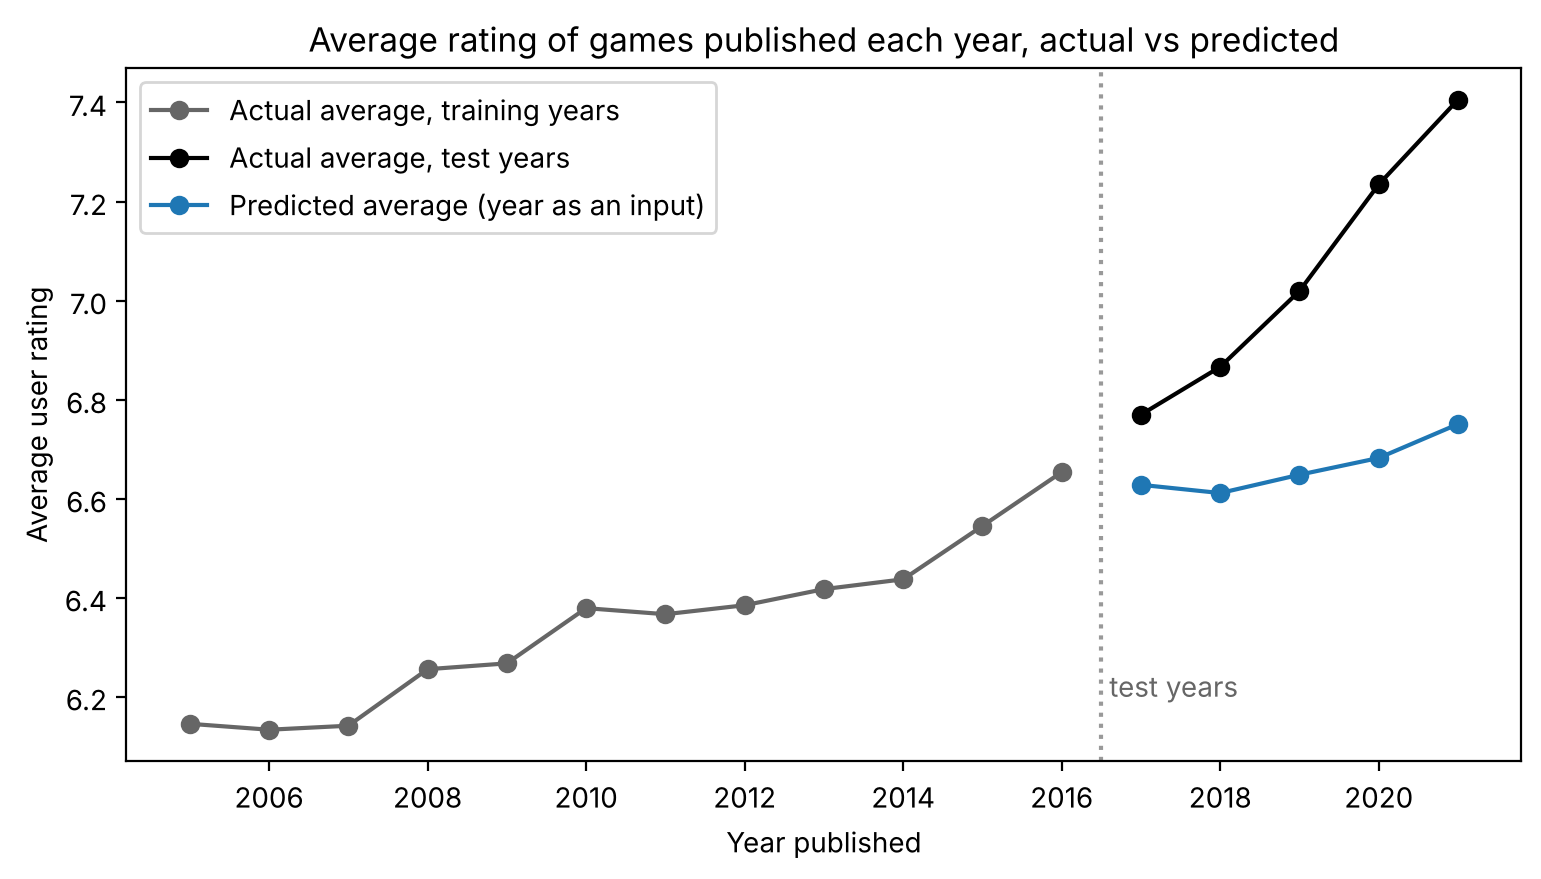

,games,average actual,average predicted,average miss (pred - actual)
test year,,,,
2017,1155,6.77,6.63,-0.14
2018,1168,6.87,6.61,-0.25
2019,1105,7.02,6.65,-0.37
2020,783,7.23,6.68,-0.55
2021,604,7.41,6.75,-0.66


In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-10. Figure: actual vs predicted average rating by year; reviewed and edited by Andrew Reicin.
yr = by_year[by_year["model"] == "Year as an input"].set_index("test year")
train_by_year = train_df[train_df["yearpublished"] >= 2005].groupby("yearpublished")["average"].mean()

plt.figure(figsize=(9, 4.5))
plt.plot(train_by_year.index, train_by_year.values, marker="o", color="0.4", label="Actual average, training years")
plt.plot(yr.index, yr["average actual"], marker="o", color="black", label="Actual average, test years")
plt.plot(yr.index, yr["average predicted"], marker="o", color=COLORS["Year as an input"], label="Predicted average (year as an input)")
plt.axvline(x=CUTOFF + 0.5, color="0.6", linestyle=":")
plt.text(CUTOFF + 0.6, 6.2, "test years", color="0.4")
plt.title("Average rating of games published each year, actual vs predicted")
plt.xlabel("Year published")
plt.ylabel("Average user rating")
plt.legend(loc="upper left")
save("08_rating_drift.png")
plt.show()

yr[["games", "average actual", "average predicted", "average miss (pred - actual)"]].round(2)

Ratings of newly published games keep rising (6.77 in 2017 to 7.41 in 2021), while predictions stay around 6.6-6.7. The model cannot follow a rise it never saw in training.

## 6. Does year still help on games newer than any in training?

A tree cannot extrapolate: every test year is beyond the last split on year, so the model treats a 2021 game exactly like a 2016 game. The check below confirms that, then compares the two versions directly.

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-10. Check: setting every test game's year to 2016 leaves the predictions unchanged; reviewed and edited by Andrew Reicin.
test_all = data[data["yearpublished"].isin(TEST_YEARS)]
X_test_all = build_inputs(test_all)
as_2016 = X_test_all.copy()
as_2016["yearpublished"] = CUTOFF
same = np.allclose(models["Year as an input"].predict(X_test_all), models["Year as an input"].predict(as_2016))
print("Predictions identical when every test game is set to", CUTOFF, ":", same)

Predictions identical when every test game is set to 2016 : True


In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-10. Year in vs year removed, every test year; reviewed and edited by Andrew Reicin.
compare = by_year[by_year["model"] != "Dummy (training mean)"].pivot(index="test year", columns="model", values="RMSE")
compare["RMSE saved by keeping year"] = compare["Year removed"] - compare["Year as an input"]
compare["year helps"] = np.where(compare["RMSE saved by keeping year"] > 0, "yes", "no")
compare.round(3)

model,Year as an input,Year removed,RMSE saved by keeping year,year helps
test year,,,,
2017,0.639,0.747,0.109,yes
2018,0.717,0.816,0.100,yes
2019,0.727,0.846,0.119,yes
2020,0.860,1.002,0.142,yes
2021,0.915,1.066,0.150,yes


In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-10. Where year sits in the tree: importance of each input; reviewed and edited by Andrew Reicin.
imp = pd.Series(models["Year as an input"].feature_importances_, index=versions["Year as an input"]).sort_values(ascending=False)
imp.head(8).round(3).to_frame("importance")

,importance
minage,0.295
yearpublished,0.258
maxplaytime,0.162
n_mechanics,0.105
mech_Roll / Spin and Move,0.072
maxplayers,0.038
cat_Wargame,0.015
minplaytime,0.012


- Year lowers the error by 0.10-0.15 in every test year and is the second most important input (0.26).
- The tree treats every game after 2016 as if published in 2016 (predictions unchanged), so year only marks a game as recent; it cannot follow the rising trend.

**Decision (Andrew Reicin): keep year as an input, with a caveat.** It improves the model in every test year, but only by marking games as recent; it cannot follow ratings that keep rising. So the model needs retraining about every 2-3 years.

Rows follow notebook 04 until Task 1's missing-value choice is in; the model is notebook 04's tree, not re-tuned, as the task says.